# 설명만으로 도구 선택하기

**이 노트북에서 할 일**

1. 공개 이름을 가리고 설명만 다른 도구 두 판을 만듭니다.
2. 메서드 `bind_tools`로 모델에게 도구를 알려 주고, 도구 호출 목록을 읽습니다.
3. 같은 질문 셋을 두 판에 세 번씩 보내, 고른 도구를 기대 도구와 견줍니다.
4. 입력 토큰과 예상 비용을 보고, 합계 도구의 설명만 바꿔 다시 봅니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 모델 요청은 모두 28번입니다.
5절에서 1번, 6절에서 두 판에 9번씩, 8절에서 9번을 보냅니다.
요금표로 센 예상 비용은 모두 합쳐 0.01달러 아래이고, 청구 금액이 아닙니다.

모델은 도구를 고르기만 하고, 이 노트북은 도구를 실행하지 않습니다.
그래서 주문 CSV는 자리만 찾아 두고 읽지 않으며, 새로 쓰는 파일도 없습니다.
Ch 4 함수와 03절 몸통 함수, Ch 6 06절 함수는 도구 파일 `order_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 30초 안에 끝났습니다.
모델 응답을 기다리는 시간은 네트워크와 실행 때에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
pandas 3.0.5와 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~6절을 읽습니다.
이름을 가린 두 판을 만들고, 모델이 고른 도구를 견주는 자리입니다.
7~8절은 입력 토큰과 예상 비용을 보고 설명 하나만 바꿔 보는 자리입니다.
이 부분은 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch19-model-tools`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 맨 위 회색 상자 두 판 도구 셋 공개 이름 같음 tool_a tool_b tool_c 설명만 다름에서 회색 상자 bind_tools 도구 명세를 요청에 실음으로 이어지고, 그 오른쪽 초록 상자 질문 셋 목록 한 건 건수와 함께 보라 상자 gpt-5.4-mini 질문마다 세 번으로 모인 뒤, 노란 상자 도구 호출 목록 고른 도구 이름과 파란 상자 count_expected 기대 도구와 견줌을 거쳐 노란 상자 기대 도구를 고른 기록 짧은 판 6 자세한 판 9 모두 9번 가운데로 끝나는 그림](attachment:04-1-이름을-가린-두-판과-채점.png)

위에서 아래로 읽습니다. 맨 위 회색 상자는 3·4절에서 만든 두 판의 도구 셋입니다.
회색 상자 `bind_tools`가 명세를 요청에 싣고, 그 오른쪽 초록 질문 셋과 함께 보라 상자 모델로 갑니다.
노란 상자 도구 호출 목록에서 고른 도구 이름을 읽어, 파란 상자 함수가 기대 도구와 견줍니다.
맨 아래 노란 상자는 6절 출력입니다.
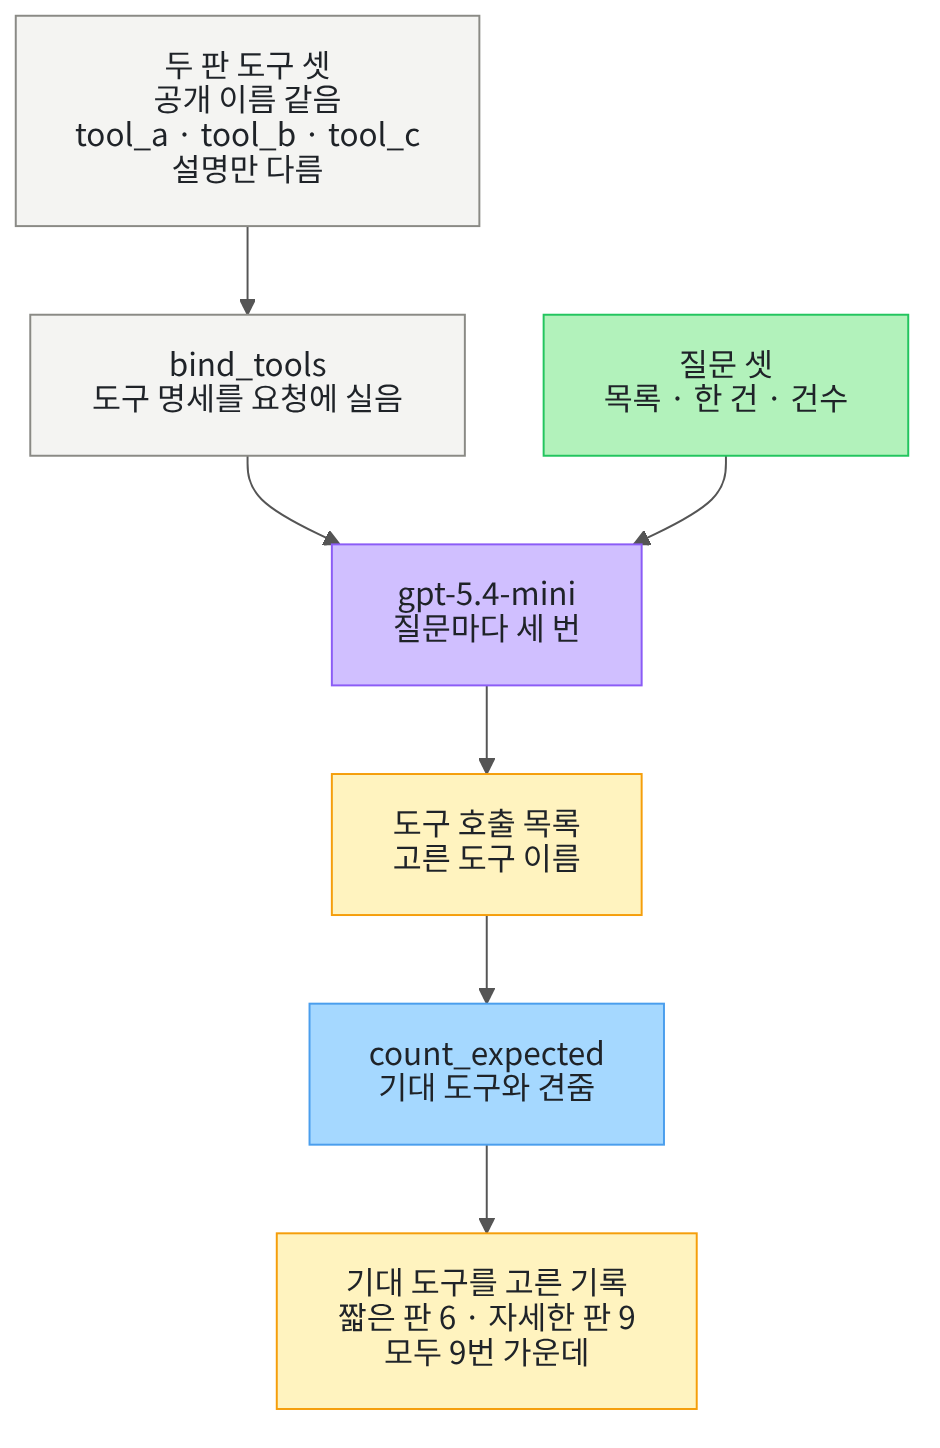

## 1. 준비

03절은 설명만 다른 두 판의 명세를 견주었지만, 모델에게 보내지는 않았습니다.
이 절은 두 판을 모델에게 알려 주고, 같은 질문에 어느 도구를 고르는지 봅니다.
이 챕터에서 모델을 부르는 첫 절이라, 준비 셀에 API 키 확인과 모델 준비가 더해집니다.

첫 셀은 패키지 다섯 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "pandas==3.0.5" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("pandas:", version("pandas"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
pandas: 3.0.5
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`·`langchain-core: 1.6.2`·`langchain-openai: 1.6.0`이 보입니다.
출력 줄 `pandas: 3.0.5`와 `python-dotenv: 1.2.3`도 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-24에 이 판으로 실행한 결과입니다.

앞에서 배운 함수는 `order_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
함수 `init_chat_model`은 Ch 6에서 모델을 만들 때 쓴 함수입니다.
도구 파일에서는 Ch 4 함수 `fetch_orders`와 03절 몸통 함수 둘을 가져옵니다.
Ch 6 06절 함수 `estimate_cost`는 이 절에서 도구 파일에 옮겨 처음 가져옵니다.

In [2]:
# 모델과 도구를 만드는 이름, 명세를 보는 함수, 도구 파일의 함수 넷을 가져옵니다
import os

from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langchain_core.utils.function_calling import convert_to_openai_tool

from order_tools import estimate_cost, fetch_orders, find_order, sum_orders

print("가져온 이름:", "os", "init_chat_model", "tool", "convert_to_openai_tool")

가져온 이름: os init_chat_model tool convert_to_openai_tool


**결과 읽기** — 출력 줄에 가져온 이름 넷이 보입니다.
도구 파일에서 가져온 함수 넷은 셀의 `from order_tools import …` 줄에 적혀 있습니다.
함수 `estimate_cost`는 Ch 6 06절 노트북과 같은 본문입니다.

다음 셀은 01~03절과 같은 방법으로 주문 CSV가 있는 프로젝트 맨 위 폴더를 찾습니다.
도구 몸통이 쓸 CSV 파일 위치를 정해 두지만, 이 절에서는 도구를 실행하지 않습니다.

In [3]:
# 노트북을 어느 폴더에서 열어도 주문 CSV를 찾게 후보 세 곳을 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part5/ch19-model-tools/data/orders.csv"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."
# CSV 파일 위치는 노트북이 정해 두는 값입니다(모델이 고를 값이 아님)
csv_path = root_path + "/labs/part5/ch19-model-tools/data/orders.csv"

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위: .`은 교재 출력을 프로젝트 맨 위에서 실행했다는 뜻입니다.
교재 출력은 실행 도구에 도구 파일 폴더를 따로 알려 준 실행이라 `.`이 찍혔습니다.
노트북을 `notebooks/` 폴더에서 열면 이 줄에 `../../../..`가 찍힙니다.
셀 안의 안내 글은 실습 폴더 맨 위도 적었지만, 도구 파일을 가져오려면 `notebooks/` 폴더에서 열어야 합니다.

## 2. 키와 모델 준비

이 절부터 모델에게 요청을 보냅니다.
모델은 Ch 6부터 써 온 `gpt-5.4-mini`이고, 과정의 같은 설정으로 부릅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [4]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도, 모델이 고르는 도구가 매번 같다고 보장하지는 않습니다.

In [5]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-24에 이 모델로 실행한 결과입니다.

## 3. 이름을 가린 짧은 판 도구 셋

03절에서는 같은 이름에 설명만 다른 두 판을 만들었습니다.
그 이름은 `get_order_by_id`처럼 하는 일을 드러냈습니다.
이름만 보고도 고를 수 있다면, 설명이 선택을 바꾸는지 가를 수 없습니다.
그래서 이 절은 두 판의 공개 이름을 똑같이 가립니다.

공개 이름은 모델에게 보이는 도구 이름입니다.
식당으로 치면 메뉴 카드 위에 붙은 이름표입니다.
이 절에서는 공개 이름을 `tool_a`·`tool_b`·`tool_c`로 두어, 이름표를 비워 둔 셈으로 만듭니다.

다음 셀은 목록 도구를 공개 이름 `tool_a`로 만듭니다.
02절 `@tool(args_schema=…)`처럼, 이번에는 괄호 안에 공개 이름을 따로 줍니다.
독스트링은 03절 짧은 판 목록 도구와 같은 한 문장입니다.

In [6]:
# 짧은 판: 목록 도구를 공개 이름 tool_a로 만들고 설명은 한 문장만 적습니다
@tool("tool_a")
def short_list(status: str):
    """주문을 찾습니다."""
    return fetch_orders(csv_path, status=status)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이름 `short_list`에는 01절에서 본 것처럼 함수가 아니라 도구가 담깁니다.
파이썬에서 부르는 이름은 `short_list`이지만, 모델이 보는 이름은 괄호 안의 `tool_a`입니다.

다음 두 셀도 같은 모양으로 한 건 도구 `tool_b`와 합계 도구 `tool_c`를 만듭니다.
몸통은 도구 파일에서 가져온 03절 몸통 함수를 한 번 부르는 한 줄입니다.

In [7]:
# 짧은 판: 한 건 도구를 공개 이름 tool_b로 만들고 설명은 한 문장만 적습니다
@tool("tool_b")
def short_get(order_id: str):
    """주문 정보를 봅니다."""
    return find_order(csv_path, order_id)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
모델이 채울 인자는 `order_id` 하나이고, CSV 파일 위치는 노트북이 정합니다.

다음 셀은 합계 도구입니다.

In [8]:
# 짧은 판: 합계 도구를 공개 이름 tool_c로 만들고 설명은 한 문장만 적습니다
@tool("tool_c")
def short_sum(status: str):
    """주문 금액을 봅니다."""
    return sum_orders(csv_path, status)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
목록 도구와 합계 도구는 인자 이름이 `status`로 같습니다.
그래서 두 도구는 공개 이름도 인자도 역할을 드러내지 않고, 설명만 다릅니다.

다음 셀은 짧은 판 도구 셋을 목록 `short_tools`에 담고 공개 이름과 설명을 봅니다.

In [9]:
# 짧은 판 도구 셋을 목록에 담고, 모델이 볼 공개 이름과 설명을 봅니다
short_tools = [short_list, short_get, short_sum]
for one_tool in short_tools:
    print(one_tool.name, "|", one_tool.description)

tool_a | 주문을 찾습니다.
tool_b | 주문 정보를 봅니다.
tool_c | 주문 금액을 봅니다.


**결과 읽기** — 출력 세 줄에서 세로 줄 앞이 공개 이름, 뒤가 도구 설명입니다.
공개 이름은 `tool_a`·`tool_b`·`tool_c`이고, 함수 이름은 출력에 없습니다.
설명은 `주문을 찾습니다.`·`주문 정보를 봅니다.`·`주문 금액을 봅니다.`로 03절 짧은 판과 같습니다.

## 4. 자세한 판 도구 셋

이번에는 같은 공개 이름으로 도구 셋을 하나 더 만들고, 03절 자세한 판 설명을 적습니다.
설명은 하는 일·언제 쓰는지·인자 뜻·내놓는 값 네 문장입니다.
함수 이름은 `detailed_list`처럼 다르게 지어, 3절의 짧은 판 도구도 그대로 남깁니다.

다음 셀은 목록 도구의 자세한 판입니다.

In [10]:
# 자세한 판: 같은 공개 이름 tool_a에 03절 자세한 판 설명 네 문장을 적습니다
@tool("tool_a")
def detailed_list(status: str):
    """주문 상태로 주문 목록을 찾습니다. 한 상태의 주문을 여러 건 볼 때 씁니다. 인자 status는 paid, pending, cancelled 가운데 하나입니다. 그 상태의 주문 줄을 딕셔너리 목록으로 내놓습니다."""
    return fetch_orders(csv_path, status=status)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
독스트링은 03절 자세한 판 목록 도구의 설명과 같은 글입니다.
공개 이름 `tool_a`와 몸통 줄은 3절 짧은 판과 같습니다.

다음 두 셀도 한 건 도구와 합계 도구의 자세한 판을 만듭니다.

In [11]:
# 자세한 판: 같은 공개 이름 tool_b에 03절 자세한 판 설명 네 문장을 적습니다
@tool("tool_b")
def detailed_get(order_id: str):
    """주문 번호로 주문 한 건을 찾습니다. 질문에 O103 같은 주문 번호가 있을 때 씁니다. 인자 order_id는 찾을 주문 번호입니다. 그 주문 한 줄을 딕셔너리로 내놓고, 없으면 None을 내놓습니다."""
    return find_order(csv_path, order_id)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
설명 둘째 문장이 질문에 주문 번호가 있을 때 이 도구를 쓴다고 적습니다.

다음 셀은 합계 도구의 자세한 판입니다.

In [12]:
# 자세한 판: 같은 공개 이름 tool_c에 03절 자세한 판 설명 네 문장을 적습니다
@tool("tool_c")
def detailed_sum(status: str):
    """주문 상태로 주문 수와 금액 합계를 셉니다. 주문 목록 대신 개수나 합계를 물을 때 씁니다. 인자 status는 paid, pending, cancelled 가운데 하나입니다. 상태·주문 수·합계를 딕셔너리로 내놓습니다."""
    return sum_orders(csv_path, status)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
설명 둘째 문장은 주문 목록 대신 개수나 합계를 물을 때 쓴다고 적습니다.
짧은 판의 합계 도구 설명에는 이런 사용 조건이 없었습니다.

다음 셀은 자세한 판 도구 셋을 목록 `detailed_tools`에 담습니다.
그리고 짧은 판과 공개 이름·입력 형식이 같은지 도구마다 봅니다.

In [13]:
# 자세한 판 도구 셋을 목록에 담고, 짧은 판과 공개 이름·입력 형식이 같은지 도구마다 봅니다
detailed_tools = [detailed_list, detailed_get, detailed_sum]
for position in range(len(detailed_tools)):
    short_tool = short_tools[position]
    detailed_tool = detailed_tools[position]
    same_name = short_tool.name == detailed_tool.name
    same_args = short_tool.args == detailed_tool.args
    print(detailed_tool.name, "| 이름 같음:", same_name, "| 입력 형식 같음:", same_args)

tool_a | 이름 같음: True | 입력 형식 같음: True
tool_b | 이름 같음: True | 입력 형식 같음: True
tool_c | 이름 같음: True | 입력 형식 같음: True


**결과 읽기** — 출력 세 줄 모두 `이름 같음: True`와 `입력 형식 같음: True`입니다.
두 판은 공개 이름과 입력 형식이 같고, 도구 설명만 다릅니다.
모델이 두 판에서 다른 도구를 고른다면, 그 차이는 설명에서 온 것입니다.

## 5. 모델에게 도구 알려 주기

지금까지 만든 도구는 파이썬 안에만 있고, 모델은 아직 모릅니다.
모델에게 도구를 알려 주는 메서드가 `bind_tools`입니다.
이 메서드는 도구마다 도구 명세를 만들어, 요청마다 함께 싣는 모델 객체를 새로 내놓습니다.
손님 자리에 메뉴판을 놓아 두는 일과 같습니다.

다음 셀은 짧은 판 도구 셋을 알려 준 모델 객체 `short_model`을 만듭니다.
인자 `parallel_tool_calls=False`는 한 응답에 도구 호출 요청을 하나까지만 담게 합니다.
여럿을 담는 경우는 05절에서 봅니다.
이 셀은 요청을 보내지 않고, 요청에 실을 명세만 봅니다.

In [14]:
# 짧은 판 도구 셋을 알려 준 모델 객체를 만들고, 요청에 실을 명세를 봅니다(요청은 아직 없음)
short_model = model.bind_tools(short_tools, parallel_tool_calls=False)
# 속성 kwargs에는 요청마다 덧붙일 값이 딕셔너리로 들어 있습니다
sent_tools = short_model.kwargs["tools"]
print("실어 보낼 명세 수:", len(sent_tools))
print("첫 명세:", sent_tools[0])
print("convert_to_openai_tool과 같은가:", sent_tools[0] == convert_to_openai_tool(short_list))

실어 보낼 명세 수: 3
첫 명세: {'type': 'function', 'function': {'name': 'tool_a', 'description': '주문을 찾습니다.', 'parameters': {'properties': {'status': {'type': 'string'}}, 'required': ['status'], 'type': 'object'}}}
convert_to_openai_tool과 같은가: True


**결과 읽기** — 출력 줄 `실어 보낼 명세 수: 3`은 도구 셋의 명세가 모두 실린다는 뜻입니다.
라벨 `첫 명세:` 뒤 딕셔너리의 이름 칸은 `tool_a`이고, 설명 칸은 짧은 판 한 문장입니다.
함수 이름 `short_list`는 명세에 없습니다.
출력 줄 `convert_to_openai_tool과 같은가: True`로, 01절 함수가 만든 명세와 같은 모양을 싣습니다.

다음 셀은 이 모델에게 질문 하나를 보냅니다.
Ch 7 05절에서 도구를 알려 주지 않은 요청은 도구 호출 목록(`tool_calls`)이 비어 있었습니다.
이번에는 도구를 알려 주었으니, 모델이 도구를 고르면 이 목록이 찹니다.

In [15]:
# 짧은 판 도구를 알려 준 모델에게 질문 하나를 보냅니다(모델 요청 1번)
response = short_model.invoke("O103 주문의 금액은 얼마야?")
print("응답 글의 길이:", len(response.content))
print("도구 호출 요청 수:", len(response.tool_calls))
print("도구 호출 목록:", response.tool_calls)

응답 글의 길이: 0
도구 호출 요청 수: 1
도구 호출 목록: [{'name': 'tool_b', 'args': {'order_id': 'O103'}, 'id': 'call_Oh4fLW9GRYPltf53ddp4s6L2', 'type': 'tool_call'}]


**결과 읽기** — 출력 줄 `응답 글의 길이: 0`은 모델이 글로 답하지 않았다는 뜻입니다.
출력 줄 `도구 호출 요청 수: 1`처럼 목록에는 딕셔너리 하나가 들어 있습니다.
칸 `name`은 공개 이름 `tool_b`, 칸 `args`는 인자 딕셔너리 `{'order_id': 'O103'}`입니다.
칸 `id`는 요청마다 새로 붙는 번호라 실행마다 다르고, 05절에서 씁니다.

이 딕셔너리 한 건을 도구 호출 요청이라고 부릅니다.
「이 도구를 이 인자로 불러 달라」고 모델이 적어 보낸 것이고, 주문 전표 한 장과 같습니다.
모델은 도구를 실행하지 않았고, 이 노트북도 실행하지 않습니다.
01절에서 본 것처럼 도구를 부르는 일은 프로그램이 하고, 그 일은 05절에서 합니다.

## 6. 질문 셋을 두 판에 보내기

이제 두 판을 같은 질문 셋으로 견줍니다.
질문은 주문 목록·주문 한 건·주문 건수를 하나씩 묻습니다.
질문마다 골라야 할 도구를 실행 전에 정해 두었고, 이를 기대 도구라고 부릅니다.
시험지의 정답표처럼 실행하기 전에 적어 두는 값이고, 딕셔너리 `expected_tools`의 값입니다.

건수 질문의 기대 도구는 합계 도구 `tool_c`입니다.
03절 자세한 판 설명이 개수나 합계를 물을 때 쓴다고 정했기 때문입니다.
다음 셀은 질문 셋과 기대 도구, 질문마다 보낼 횟수를 정합니다.

In [16]:
# 질문 셋과 기대 도구: 03절 자세한 판 설명의 사용 조건을 보고 실행 전에 정했습니다
expected_tools = {
    "결제된(paid) 주문 목록을 보여 줘.": "tool_a",
    "O103 주문의 금액은 얼마야?": "tool_b",
    "결제된(paid) 주문은 모두 몇 건이야?": "tool_c",
}
repeats = 3
print("질문 수:", len(expected_tools), "| 질문마다 보낼 횟수:", repeats)

질문 수: 3 | 질문마다 보낼 횟수: 3


**결과 읽기** — 출력 줄 `질문 수: 3 | 질문마다 보낼 횟수: 3`입니다.
한 판에 요청을 9번 보냅니다.

다음 셀은 응답 하나에서 도구 호출 목록의 도구 이름만 모으는 함수입니다.
딕셔너리마다 칸 `name`의 값을 꺼내 목록에 담습니다.

In [17]:
# 응답 하나에서 도구 호출 목록의 도구 이름만 모아 목록으로 내놓습니다
def tool_call_names(response):
    names = []
    for call in response.tool_calls:
        names.append(call["name"])
    return names

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `tool_call_names`는 도구 이름 목록을 내놓습니다.
모델이 도구를 고르지 않으면 빈 목록이 나옵니다.

다음 셀은 질문마다 정한 횟수만큼 요청을 보내고 기록하는 함수입니다.
기록 한 줄은 요청 한 번이고, 질문·고른 도구·사용량 세 칸을 담습니다.

In [18]:
# 질문마다 정한 횟수만큼 요청을 보내고, 고른 도구 이름과 사용량을 기록합니다
def ask_questions(bound_model, expected_tools, repeats):
    records = []
    for question in expected_tools:
        for turn in range(repeats):
            response = bound_model.invoke(question)
            names = tool_call_names(response)
            records.append({"질문": question, "고른 도구": names, "사용량": response.usage_metadata})
    return records

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `ask_questions`는 질문 수 곱하기 횟수만큼 요청을 보냅니다.
사용량은 Ch 6 06절처럼 응답의 `usage_metadata`에서 읽습니다.

다음 셀은 짧은 판 모델로 질문 셋을 세 번씩 보냅니다.
실행 전에 예상해 봅니다.
한 건 질문은 인자 `order_id`가 있는 `tool_b`를 고를 것입니다.
목록과 건수 질문은 설명만으로 가려야 해서, 어느 쪽을 고를지 알 수 없습니다.

In [19]:
# 짧은 판 도구 셋으로 질문 셋을 세 번씩 보냅니다(모델 요청 9번)
short_records = ask_questions(short_model, expected_tools, repeats)
for record in short_records:
    print(record["질문"], "|", record["고른 도구"])

결제된(paid) 주문 목록을 보여 줘. | ['tool_a']
결제된(paid) 주문 목록을 보여 줘. | ['tool_a']
결제된(paid) 주문 목록을 보여 줘. | ['tool_a']
O103 주문의 금액은 얼마야? | ['tool_b']
O103 주문의 금액은 얼마야? | ['tool_b']
O103 주문의 금액은 얼마야? | ['tool_b']
결제된(paid) 주문은 모두 몇 건이야? | ['tool_a']
결제된(paid) 주문은 모두 몇 건이야? | ['tool_a']
결제된(paid) 주문은 모두 몇 건이야? | ['tool_a']


**결과 읽기** — 목록 질문 세 줄은 모두 `['tool_a']`, 한 건 질문 세 줄은 모두 `['tool_b']`입니다.
건수 질문 세 줄은 모두 `['tool_a']`입니다.
짧은 판에서 모델은 건수 질문에 기대 도구 `tool_c`가 아니라 목록 도구를 골랐습니다.
짧은 판 설명 셋에는 건수를 물을 때 어느 도구를 쓰는지 적혀 있지 않았습니다.

다음 셀은 자세한 판 도구 셋을 알려 준 모델을 만들고, 같은 질문 셋을 세 번씩 보냅니다.
실행 전에 예상해 봅니다.
합계 도구 설명에 개수를 물을 때 쓴다고 적었으니, 건수 질문에 `tool_c`를 고를 것입니다.

In [20]:
# 자세한 판 도구 셋을 알려 준 모델로 같은 질문 셋을 세 번씩 보냅니다(모델 요청 9번)
detailed_model = model.bind_tools(detailed_tools, parallel_tool_calls=False)
detailed_records = ask_questions(detailed_model, expected_tools, repeats)
for record in detailed_records:
    print(record["질문"], "|", record["고른 도구"])

결제된(paid) 주문 목록을 보여 줘. | ['tool_a']
결제된(paid) 주문 목록을 보여 줘. | ['tool_a']
결제된(paid) 주문 목록을 보여 줘. | ['tool_a']
O103 주문의 금액은 얼마야? | ['tool_b']
O103 주문의 금액은 얼마야? | ['tool_b']
O103 주문의 금액은 얼마야? | ['tool_b']
결제된(paid) 주문은 모두 몇 건이야? | ['tool_c']
결제된(paid) 주문은 모두 몇 건이야? | ['tool_c']
결제된(paid) 주문은 모두 몇 건이야? | ['tool_c']


**결과 읽기** — 건수 질문 세 줄이 모두 `['tool_c']`로 바뀌었습니다.
목록 질문은 `['tool_a']`, 한 건 질문은 `['tool_b']`로 짧은 판과 같습니다.
두 판은 설명만 달랐고, 선택이 갈린 곳은 건수 질문 하나였습니다.

다음 셀은 기록마다 고른 도구가 기대 도구 하나뿐인지 보고 그 수를 세는 함수입니다.
고른 도구 이름만 보고 인자는 보지 않으므로, 이 절에서는 선택 채점이라고 부릅니다.
정답표로 답안의 번호만 맞춰 보는 일과 같습니다.

In [21]:
# 기록마다 고른 도구가 기대 도구 하나뿐인지 보고, 맞은 기록 수를 셉니다
def count_expected(records, expected_tools):
    matched = 0
    for record in records:
        expected = [expected_tools[record["질문"]]]
        if record["고른 도구"] == expected:
            matched = matched + 1
    return matched

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `count_expected`는 기대 도구를 고른 기록 수를 정수로 내놓습니다.
도구를 고르지 않았거나 둘 이상 골랐으면 맞지 않은 기록으로 셉니다.

다음 셀은 두 판의 기록을 같은 함수로 셉니다.

In [22]:
# 두 판에서 기대 도구를 고른 기록 수를 견줍니다
short_matched = count_expected(short_records, expected_tools)
detailed_matched = count_expected(detailed_records, expected_tools)
print("짧은 판 | 기대 도구를 고른 기록:", short_matched, "/", len(short_records))
print("자세한 판 | 기대 도구를 고른 기록:", detailed_matched, "/", len(detailed_records))

짧은 판 | 기대 도구를 고른 기록: 6 / 9
자세한 판 | 기대 도구를 고른 기록: 9 / 9


**결과 읽기** — 출력 줄 `짧은 판 | 기대 도구를 고른 기록: 6 / 9`입니다.
출력 줄 `자세한 판 | 기대 도구를 고른 기록: 9 / 9`입니다.
짧은 판에서 맞지 않은 세 기록은 모두 건수 질문이었습니다.
노트북 밖에서 두 판을 다섯 번씩 보냈을 때도, 질문마다 고른 도구는 다섯 번 모두 같았습니다.

## 7. 입력 토큰과 예상 비용

03절에서는 명세 글자 수를 셌고, 토큰 수는 요청을 보내야 안다고 했습니다.
이제 요청을 보냈으니 사용량의 입력 토큰을 볼 수 있습니다.
다음 셀은 두 판의 첫 기록, 곧 같은 목록 질문의 입력 토큰을 견줍니다.

In [23]:
# 두 판의 첫 기록(목록 질문)에서 입력 토큰 수를 견줍니다
short_input = short_records[0]["사용량"]["input_tokens"]
detailed_input = detailed_records[0]["사용량"]["input_tokens"]
print("짧은 판 입력 토큰:", short_input)
print("자세한 판 입력 토큰:", detailed_input)
print("늘어난 입력 토큰:", detailed_input - short_input)

짧은 판 입력 토큰: 177
자세한 판 입력 토큰: 330
늘어난 입력 토큰: 153


**결과 읽기** — 출력 줄 `짧은 판 입력 토큰: 177`과 `자세한 판 입력 토큰: 330`입니다.
출력 줄 `늘어난 입력 토큰: 153`만큼 자세한 판 요청이 깁니다.
질문 글과 공개 이름, 입력 형식이 같으니 늘어난 토큰은 설명이 길어진 몫입니다.
도구 명세는 요청마다 입력으로 실려, 설명이 길면 입력 토큰도 늘어납니다.

다음 셀은 기록마다 예상 비용을 세어 더하는 함수입니다.
Ch 6 06절 함수 `estimate_cost`에 기록의 사용량과 요금 셋을 넘깁니다.
예상 비용은 요금표로 어림한 값이고 청구 금액이 아닙니다.

In [24]:
# 기록마다 사용량으로 예상 비용을 세어 모두 더합니다(Ch 6 06절 함수 estimate_cost를 씁니다)
def records_cost(records, prices):
    total = 0
    for record in records:
        cost = estimate_cost(
            record["사용량"], prices["ordinary_input"], prices["cached_input"], prices["output"]
        )
        total = total + cost
    return total

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `records_cost`는 기록 목록의 예상 비용 합을 달러로 내놓습니다.

다음 셀은 Ch 6 06절 요금표로 두 판의 예상 비용을 셉니다.
노트북 밖에서 이 절의 요청을 보냈을 때 캐시 입력은 모두 0이었습니다.

In [25]:
# Ch 6 06절 요금표(100만 토큰당 달러)로 두 판 요청의 예상 비용을 셉니다(요청 없음)
pricing_date = "2026-09-17"
mini_prices = {"ordinary_input": 0.75, "cached_input": 0.075, "output": 4.50}
short_cost = records_cost(short_records, mini_prices)
detailed_cost = records_cost(detailed_records, mini_prices)
print("요금 확인 날짜:", pricing_date)
print("짧은 판 요청 9번 예상 비용(달러):", round(short_cost, 6))
print("자세한 판 요청 9번 예상 비용(달러):", round(detailed_cost, 6))

요금 확인 날짜: 2026-09-17
짧은 판 요청 9번 예상 비용(달러): 0.001906
자세한 판 요청 9번 예상 비용(달러): 0.002938


**결과 읽기** — 출력 줄 `요금 확인 날짜: 2026-09-17`은 Ch 6 06절 요금표를 확인한 날짜입니다.
짧은 판 요청 9번은 `0.001906`달러, 자세한 판 요청 9번은 `0.002938`달러입니다.
노트북 밖 확인에서 출력 토큰 수는 두 판이 질문마다 같아, 비용 차이는 입력 토큰 몫입니다.
5절의 요청 1번과 8절의 요청 9번은 이 합에 넣지 않았습니다.

## 8. 값 바꿔 보기 · 합계 도구 설명만 바꾸기

바꿀 값은 합계 도구의 설명 하나입니다.
짧은 판 셋에서 `tool_c`만 자세한 판으로 바꾸고, `tool_a`·`tool_b`는 짧은 판 그대로 둡니다.
같은 질문 셋을 세 번씩 보냅니다.
실행 전에 예상해 봅니다.
건수 질문의 선택이 `tool_c`로 바뀌고, 나머지 두 질문은 그대로일 것입니다.

In [26]:
# 바꿀 값: 짧은 판 셋에서 합계 도구 하나만 자세한 판으로 바꿔 알려 줍니다(모델 요청 9번)
mixed_tools = [short_list, short_get, detailed_sum]
mixed_model = model.bind_tools(mixed_tools, parallel_tool_calls=False)
mixed_records = ask_questions(mixed_model, expected_tools, repeats)
for record in mixed_records:
    print(record["질문"], "|", record["고른 도구"])

결제된(paid) 주문 목록을 보여 줘. | ['tool_a']
결제된(paid) 주문 목록을 보여 줘. | ['tool_a']
결제된(paid) 주문 목록을 보여 줘. | ['tool_a']
O103 주문의 금액은 얼마야? | ['tool_b']
O103 주문의 금액은 얼마야? | ['tool_b']
O103 주문의 금액은 얼마야? | ['tool_b']
결제된(paid) 주문은 모두 몇 건이야? | ['tool_c']
결제된(paid) 주문은 모두 몇 건이야? | ['tool_c']
결제된(paid) 주문은 모두 몇 건이야? | ['tool_c']


**결과 읽기** — 건수 질문 세 줄이 모두 `['tool_c']`입니다.
목록 질문은 `['tool_a']`, 한 건 질문은 `['tool_b']`로 짧은 판과 같습니다.
합계 도구 설명을 자세한 판 네 문장으로 바꾸자, 건수 질문의 선택이 바뀌었습니다.
네 문장 가운데 어느 문장이 선택을 바꿨는지는 이번에 가르지 않았습니다.

다음 셀은 이 판의 기록을 같은 함수로 셉니다.

In [27]:
# 합계 도구만 바꾼 판에서 기대 도구를 고른 기록 수를 셉니다
mixed_matched = count_expected(mixed_records, expected_tools)
print("합계 도구만 바꾼 판 | 기대 도구를 고른 기록:", mixed_matched, "/", len(mixed_records))

합계 도구만 바꾼 판 | 기대 도구를 고른 기록: 9 / 9


**결과 읽기** — 출력 줄 `합계 도구만 바꾼 판 | 기대 도구를 고른 기록: 9 / 9`입니다.
짧은 판의 여섯 기록에서 건수 질문 세 기록만큼 늘었습니다.
목록 도구의 설명은 짧은 판 그대로인데도, 모델은 건수 질문에 합계 도구를 골랐습니다.

선택을 바꾼 것은 합계 도구 설명을 자세한 판 네 문장으로 바꾼 일이었습니다.
네 문장에는 하는 일(주문 수와 금액 합계)과 사용 조건(개수나 합계를 물을 때)이 함께 있습니다.
어느 문장이 선택을 바꿨는지는 이번에 가르지 않았습니다.

## 정리

1. `bind_tools`로 도구를 알려 주자, 모델은 글 대신 도구 호출 요청을 적어 보냈습니다.
2. 공개 이름을 가리고 설명만 바꾸자, 건수 질문에서 짧은 판은 목록 도구, 자세한 판은 합계 도구를 골랐습니다.
3. 자세한 판은 설명이 길어 요청마다 입력 토큰과 예상 비용이 늘었습니다.

05절에서는 한 응답에 도구 호출 요청이 여럿 오는 경우를 보고, 도구를 실제로 실행합니다.